In [62]:
%pip install -q landingai pillow matplotlib gTTS

In [63]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Create a simple RGB image
image = Image.new("RGB", (100, 100), color="white")

# Encode into memory instead of saving to a special file object
buffer = io.BytesIO()
image.save(buffer, format="JPEG")

print("Image encoding successful!")
print("Encoded bytes:", len(buffer.getvalue()))

Pillow version: 10.4.0
Image encoding successful!
Encoded bytes: 823


In [64]:
%pip install landingai

In [65]:
import sys
import PIL
from PIL import Image
import io

print("Python:", sys.version)
print("Pillow:", PIL.__version__)

# Test whether Pillow can save an image normally
try:
    test_image = Image.new("RGB", (100, 100), "white")
    buffer = io.BytesIO()
    test_image.save(buffer, format="PNG")
    print("PASS: Pillow image encoding works.")
except Exception as e:
    print("FAIL:", repr(e))

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pillow: 10.4.0
PASS: Pillow image encoding works.


In [66]:

from google.colab import userdata
from landingai.predict import Predictor

API_KEY = userdata.get("LANDINGAI_API_KEY")

ENDPOINT_ID = "5d826948-49e2-4674-b323-fc014afd53d2"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized.")


LandingAI predictor initialized.


In [67]:

from google.colab import files
from PIL import Image
import io
import numpy as np

uploaded = files.upload()
filename = next(iter(uploaded))

with Image.open(io.BytesIO(uploaded[filename])) as im:
    image = im.convert("RGB").copy()

image_array = np.array(image)

print("Image size:", image.size)
print("Image array shape:", image_array.shape)


Saving 360_F_599439457_KN5ZsSTpnH8VaANWnVfR15zabST94oHy.webp to 360_F_599439457_KN5ZsSTpnH8VaANWnVfR15zabST94oHy (4).webp
Image size: (500, 300)
Image array shape: (300, 500, 3)


In [68]:

predictions = predictor.predict(image_array)

print("Prediction count:", len(predictions))

for i, prediction in enumerate(predictions, start=1):
    print(f"\nPrediction {i}:")
    print(prediction)


Prediction count: 0


Wildfire Cognitive Assistant
Upload an image for analysis.


Saving fire.png to fire (4).png


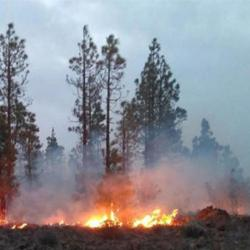


Raw model predictions:
[]
No predictions returned by the model.


In [69]:

from google.colab import files
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io

def wildfire_assistant():

    print("Wildfire Cognitive Assistant")
    print("Upload an image for analysis.")

    # 1. Upload image
    uploaded = files.upload()
    if not uploaded:
        print("No image uploaded.")
        return

    filename = next(iter(uploaded))

    with Image.open(io.BytesIO(uploaded[filename])) as img:
        image = img.convert("RGB").copy()

    display(image)

    # 2. Run the connected LandingAI model
    predictions = predictor.predict(np.array(image))

    print("\nRaw model predictions:")
    print(predictions)

    if not predictions:
        print("No predictions returned by the model.")
        return

    # 3. Read the ClassificationPrediction object
    prediction = predictions[0]

    predicted_label = getattr(prediction, "label_name", None)
    predicted_index = getattr(prediction, "label_index", None)
    confidence = getattr(prediction, "score", None)

    print("Predicted label:", predicted_label)
    print("Predicted class index:", predicted_index)
    print("Confidence:", confidence)

    # 4. Interpret the model's class index
    # Assumption: index 1 = Fire, index 0 = No Fire
    if predicted_index == 1:
        result = "Fire! Fire!"
        print("🔥 FIRE DETECTED!")
    elif predicted_index == 0:
        result = "Safe"
        print("No-fire class predicted.")
    else:
        result = "Unable to determine"
        print("Unknown class index.")

    display(Markdown(f"### Assistant response: **{result}**"))

    # 5. Generate audio response
    if result != "Unable to determine":
        speech = gTTS(text=result, lang="en")
        speech.save("wildfire_response.mp3")

        display(Audio("wildfire_response.mp3", autoplay=False))
        files.download("wildfire_response.mp3")


wildfire_assistant()


In [70]:
print(type(predictor), ENDPOINT_ID)
preds = predictor.predict(image)          # try the PIL image, not the numpy array
print(len(preds), preds)

# test the model on a few different images, one clearly fire, one clearly not

<class 'landingai.predict.cloud.Predictor'> 5d826948-49e2-4674-b323-fc014afd53d2
0 []


In [71]:
if not predictions:
    result = "No fire detected"
    print("Model returned no predictions.")
else:
    prediction = predictions[0]
    label = getattr(prediction, "label_name", "").lower()
    score = getattr(prediction, "score", None)
    print("Label:", label, "Score:", score)

    if "fire" in label and "no" not in label:
        result = "Fire! Fire!"
    else:
        result = "Safe"

display(Markdown(f"### Assistant response: **{result}**"))

speech = gTTS(text=result, lang="en")
speech.save("wildfire_response.mp3")
display(Audio("wildfire_response.mp3", autoplay=False))
files.download("wildfire_response.mp3")

Model returned no predictions.


### Assistant response: **No fire detected**

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>